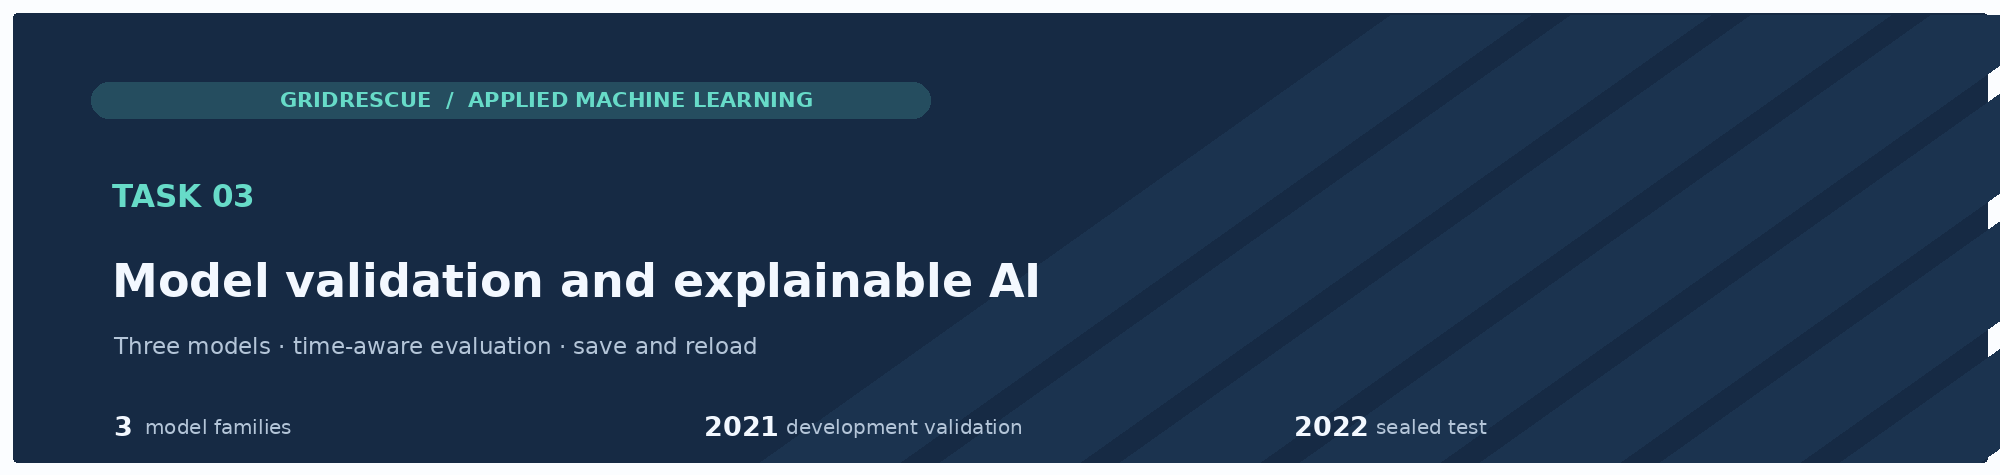

*GridRescue Task 03 — algorithm research, honest evaluation and explainability*

# GridRescue · Task 03 — Model Development & Explainable AI

**Applied Machine Learning · Training, time-aware cross-validation, model comparison and persistence**

> **Scope:** 2018–2021 development experiments. The illustrated diagram describes the evaluation protocol. The measured results below come from the local county cohort.

### Navigate directly to a section

| Jump to section | What you will learn / verify |
|---|---|
| [00 · Data readiness](#task3-ready) | Python, dataset, feature order and target approval |
| [01 · Algorithm research](#task3-research) | Logistic Regression, Decision Tree, Random Forest |
| [02 · Model pipeline](#task3-pipeline) | Fold-specific imputation and scaling |
| [03 · Chronological cross-validation](#task3-cv) | Folds, scoring and overfitting checks |
| [04 · Hyperparameter tuning](#task3-tuning) | Transparent search and bounded cost |
| [05 · Model comparison and diagnostics](#task3-results) | Development scores, runtime, errors and calibration |
| [06 · Explainable AI](#task3-xai) | Global and local evidence |
| [07 · Feature ablation](#task3-ablation) | With versus without engineered features |
| [08 · Freeze winner and save](#task3-freeze) | Fully fitted reproducible pipeline |
| [09 · Sealed 2022 final test](#task3-sealed) | Explicit user approval required |
| [10 · Evidence-based handoff](#task3-report) | Final report and app contract |

**The experiment protocol:** train and tune using 2018–2020 only; compare approved candidates on the 2021 development validation; freeze the winner without examining 2022. Refit the frozen specification on 2018–2021, and **run the sealed final evaluation only once after approval**. All learned preprocessing must be fitted on each training fold; no data leakage.


<a id="task3-ready"></a>
## 00. Reproducibility and data readiness

**Requirements before executing:** Run Task 1/2 pipelines on actual source files, verify the 2018–2021 three-county Gold and label-audit artifacts and review `reports/target_approval.json` and persisted preparation reports. The Big Data Spark work is separate from the bounded modeling table collected into pandas. The county dataset should have about **406,240 eligible train+validation anchors** in the previously verified extraction, subject to rerun and exact version matching; it is not the 400k January prefix.

**Dependencies:** Python 3.12 compatible environment, PySpark, pandas, numpy, scikit-learn, matplotlib, joblib. We do not train a 122-million-row scikit-learn Random Forest locally. The Spark source scope is much larger than the ML cohort.

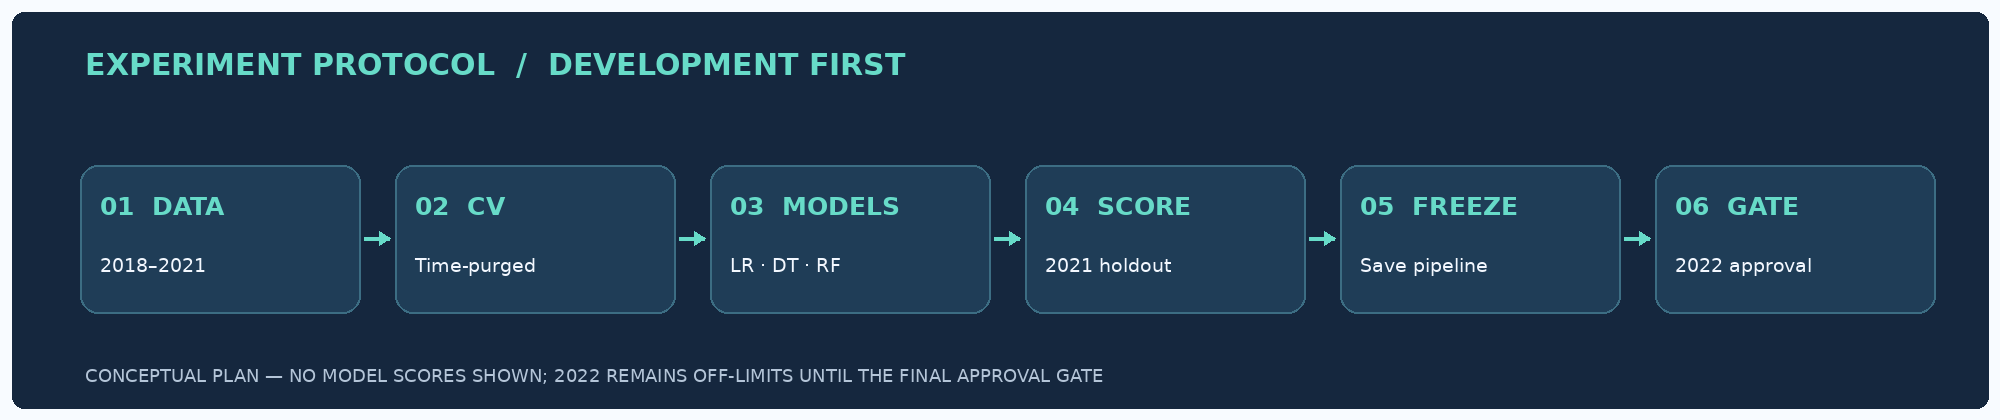

*Conceptual chronological protocol; not measured model performance*

In [1]:
from pathlib import Path
import inspect
import sys

# Search upward so the same notebook runs from the root or notebooks folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/gridrescue/experiment.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the GridRescue repository.')
sys.path.insert(0, str(ROOT / 'src'))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Code, Markdown, display
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, brier_score_loss,
                             precision_recall_curve, roc_curve)
from gridrescue.experiment import (approved, cross_validate, digest, fingerprint, fit,
                                   full_fit, load_development, probability, run_development,
                                   write_json)
from gridrescue.inference import freeze_pipeline, verify_development_reload
from gridrescue.modeling import (FEATURE_COLUMNS, MODEL_NAMES, SEARCH,
                                 chronological_folds, classification_metrics, make_model)

RANDOM_SEED = 17
REPORT_DIR = ROOT / 'reports/modeling'
# Read the approved target and fixed three counties before loading modeling data.
approval = approved(ROOT)
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
print('Approved county FIPS:', approval['county_fips'])

Python: 3.12.14 | scikit-learn: 1.9.1
Approved county FIPS: ['06037', '12086', '48201']


In [2]:
import re as _gr_re

def _gr_style_dataframe_html(source):
    """Return readable notebook HTML for a pandas table, or pass other HTML through."""
    if not source or '<table' not in source or 'dataframe' not in source:
        return source
    if 'data-gridrescue-theme=' in source:
        return source

    source = _gr_re.sub(
        r'<table\b([^>]*)>',
        lambda m: '<table' + m.group(1) +
                  ' data-gridrescue-theme="high-contrast" style="border-collapse:collapse !important; '
                  'background:#142334 !important; color:#eef5ff !important; width:100% !important; '
                  'font-size:13px !important; line-height:1.48 !important;">',
        source, count=1,
    )

    def _cells(section, header=False):
        """Color this HTML cell group, using teal for headings and navy for data."""
        def _paint(match):
            """Render one HTML table cell with a contrasting font color."""
            tag, attrs = match.group(1), match.group(2)
            if header:
                color = '#e5f9f6'
                bg = '#164654'
                weight = '700'
            else:
                bg = section['bg']
                color = '#96ddd5' if tag == 'th' else '#eef5ff'
                weight = '600' if tag == 'th' else '400'
            style = (
                'background-color:' + bg + ' !important; '
                'color:' + color + ' !important; '
                'border-bottom:1px solid #31495e !important; '
                'padding:8px 12px !important; '
                'text-align:left !important; vertical-align:top !important; '
                'white-space:normal !important; overflow-wrap:anywhere !important; '
                'font-weight:' + weight + ' !important;'
            )
            # Pandas may add inline attributes to header/index cells.
            attrs = _gr_re.sub(r'\sstyle\s*=\s*(["\']).*?\1', '', attrs, flags=_gr_re.S)
            return '<' + tag + attrs + ' style="' + style + '">'
        return _gr_re.sub(r'<(th|td)\b([^>]*)>', _paint, section['body'], flags=_gr_re.I)

    def _paint_head(match):
        """Return the heading section with the fixed teal style."""
        section = {'bg':'#164654','body':match.group(2)}
        return match.group(1) + _cells(section, header=True) + match.group(3)

    def _paint_body(match):
        """Return the data section with alternating navy rows."""
        body = match.group(2)
        num = [0]
        def _row(row):
            """Color one data row and advance the stripe counter."""
            color = '#1c3045' if num[0] % 2 == 0 else '#142638'
            num[0] += 1
            return _cells({'bg':color,'body':row.group(0)})
        body = _gr_re.sub(r'<tr\b[^>]*>.*?</tr>', _row, body, flags=_gr_re.S|_gr_re.I)
        return match.group(1) + body + match.group(3)

    source = _gr_re.sub(r'(<thead\b[^>]*>)(.*?)(</thead>)', _paint_head, source, flags=_gr_re.S|_gr_re.I)
    source = _gr_re.sub(r'(<tbody\b[^>]*>)(.*?)(</tbody>)', _paint_body, source, flags=_gr_re.S|_gr_re.I)
    return source

# Register an explicit formatter: display(df) and display(SparkFrame.toPandas())
# remain readable after re-execution, without modifying each analysis cell.
get_ipython().display_formatter.formatters['text/html'].for_type(
    pd.DataFrame, lambda frame: _gr_style_dataframe_html(frame._repr_html_())
)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#162A44',
    'axes.facecolor': '#162A44',
    'savefig.facecolor': '#162A44',
    'axes.edgecolor': '#7596A7',
    'axes.labelcolor': '#EEF5FF',
    'text.color': '#EEF5FF',
    'xtick.color': '#D2E3EE',
    'ytick.color': '#D2E3EE',
    'grid.color': '#36546B',
    'axes.prop_cycle': plt.cycler(color=['#6DE4D7', '#FFB66D', '#C4ABFF']),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.autolayout': True,
})
print('GridRescue readable dark-table and chart styling enabled (display only).')


GridRescue readable dark-table and chart styling enabled (display only).


### Data access — 2018–2021 development cohort

The shared loader checks the Spark label-audit persistence report and Parquet part hashes. It reads the bounded county artifact into pandas and verifies observed outcomes, unique keys and UTC split boundaries before fitting. The January prefixes stay separate.

In [3]:
display(pd.DataFrame({'position': range(1, 14), 'predictor': FEATURE_COLUMNS}))
# Load only hash-verified Spark Gold county parts and reconcile counts against the audit.
frame = load_development(ROOT)
# The fingerprint includes data bytes, model source, target authorization and library versions.
run_hash, inputs = fingerprint(ROOT)
# Boolean masks select rows for the two chronological roles without changing row order.
train = frame.loc[frame.split == 'train']
validation = frame.loc[frame.split == 'validation']
display(frame.groupby(['split', 'candidate_y']).size().rename('rows').reset_index())
by_year = frame.groupby([frame.timestamp.dt.year.rename('year'), 'fips_code'])
display(by_year.agg(eligible=('candidate_y', 'size'), positives=('candidate_y', 'sum')).reset_index())
print(f"{len(frame):,} eligible anchors from {inputs['data_path']}")

position             predictor
0          1       customers_out_t
1          2               lag_15m
2          3               lag_60m
3          4             delta_60m
4          5      rolling_mean_60m
5          6  rolling_variance_60m
6          7     history_slots_60m
7          8              hour_utc
8          9           weekday_utc
9         10             month_utc
10        11       lag_15m_missing
11        12       lag_60m_missing
12        13     delta_60m_missing

split  candidate_y    rows
0       train            0  192804
1       train            1  110987
2  validation            0   68730
3  validation            1   33719

year fips_code  eligible  positives
0   2018     06037     32580      14063
1   2018     12086     33686      10863
2   2018     48201     33535      11209
3   2019     06037     34339      15828
4   2019     12086     32854       9664
5   2019     48201     34156      11276
6   2020     06037     34773      15799
7   2020     12086     34047      10338
8   2020     48201     33821      11947
9   2021     06037     34476      14820
10  2021     12086     34057      10113
11  2021     48201     33916       8786

406,240 eligible anchors from data/windows/gold/county/label_audit


<a id="task3-research"></a>
## 01. Model research — three genuinely different algorithms

| Model | How it works | Why compare it? | Limitations | Hyperparameters |
|---|---|---|---|---|
| [Logistic Regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) | Learns linear **log-odds** `z = w·x + b`, maps through sigmoid, fits coefficients by minimizing regularized logistic loss | Interpretable binary baseline, fast and useful to assess linear information | Nonlinear interactions require engineering; correlated features complicate coefficient attribution | `C`, solver, regularization, `max_iter` |
| [Decision Tree](https://scikit-learn.org/stable/modules/tree.html) | Recursively chooses splits that reduce class impurity, such as Gini; leaf frequencies generate scores | Captures interactions and thresholds; readable decision rules | Unrestricted trees can overfit; can be unstable | `max_depth`, `min_samples_leaf`, `min_samples_split` |
| [Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees) | Trains many trees on bootstrap rows with feature randomness, aggregates their predictions | Captures nonlinear relationships and often reduces single-tree variance | More CPU/memory, less transparent, uncalibrated raw scores | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |

All models use the **same X/y, training dates and validation anchors**. CV below means chronological cross-validation. Every saved setting and result must come from a real run.

**Important preprocessing nuance:** Task 2 fitted a Spark `Imputer + VectorAssembler + StandardScaler` for the teaching cohort and verified source values. Here a **scikit-learn median imputer and standard scaler are refitted inside each training fold** using *raw 13-column county features*. These use equivalent methodological stages, but Spark's sample-std and sklearn's population-std conventions may differ slightly. The final app will reuse the **saved sklearn pipeline**, avoiding numerical mismatch.

<a id="task3-pipeline"></a>
## 02. Set up the leakage-safe estimator pipeline

`SimpleImputer.fit` learns training-column medians; `StandardScaler.fit` learns training means and standard deviations; the estimator's `fit` learns model parameters. `transform` on validation **reuses** those learned statistics. If we imputed or scaled the full development table before cross-validation, each validation fold would influence training and leak information.

We retain the **13-feature baseline**, including a known redundant missingness flag, to compare exactly the same Task 2 contract. The feature-ablation experiment later measures whether engineering helps rather than silently changing the feature list.

In [4]:
# Display the exact shared factory, including where the imputer and scaler are created.
display(Code(inspect.getsource(make_model), language='python'))
# get_params() makes the actual installed defaults visible before fitting.
display(pd.DataFrame([{'model': name, 'classifier': repr(make_model(name).named_steps['classifier'])}
                      for name in MODEL_NAMES]))

def make_model(name,parameters=None):
    """Build an unfitted imputer, scaler and named classifier using ordered numeric inputs."""
    if name=='Logistic Regression':
        estimator=LogisticRegression(random_state=17)
    elif name=='Random Forest':
        estimator=RandomForestClassifier(random_state=17,n_jobs=2)
    elif name=='Decision Tree':
        estimator=DecisionTreeClassifier(random_state=17)
    else:
        raise ValueError(f'Unknown model: {name}')
    if parameters:
        estimator.set_params(**parameters)
    # Fit the medians before fitting the scaler on the resulting filled-in values.
    numeric=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
    prepare=ColumnTransformer([('numeric',numeric,FEATURE_COLUMNS)],remainder='drop')
    return Pipeline([('prepare',prepare),('classifier',estimator)])

model                                         classifier
0  Logistic Regression                LogisticRegression(random_state=17)
1        Decision Tree            DecisionTreeClassifier(random_state=17)
2        Random Forest  RandomForestClassifier(n_jobs=2, random_state=17)

### Metrics and classification interpretation

**AP** integrates precision over ranked recall thresholds and is informative for imbalanced labels. **Precision** asks how many predicted escalations were observed; **recall** asks how many observed escalations were identified; **F1** balances precision and recall. **Accuracy** can be misleading when class 0 dominates. ROC-AUC measures ranking across thresholds; the confusion matrix shows true negatives/false positives/false negatives/true positives. The **0.5 decision rule** is the classifier default, not an approved operations alert threshold.

Use `model.predict` for labels (handles implementation-specific 0.5 ties) and `predict_proba[:, 1]` for score-based ranking; don't manually assume calibration.

**Primary selection metric:** average precision (AP) emphasizes the escalation class and compares score rankings without selecting a threshold. A constant-score baseline has AP equal to positive prevalence. Trapezoidal PR-AUC is reported separately because it interpolates precision and recall differently.

In [5]:
# This helper computes threshold metrics and ranking metrics from the same score array.
display(Code(inspect.getsource(classification_metrics), language='python'))

def classification_metrics(y,probabilities):
    """Return threshold metrics and, for two-class cohorts, ranking metrics."""
    y=np.asarray(y,dtype=int)
    probabilities=np.asarray(probabilities,dtype=float)
    if len(y)!=len(probabilities) or not len(y) or not np.isfinite(probabilities).all():
        raise ValueError('Invalid prediction array')
    prediction=(probabilities>0.5).astype(int)
    two_classes=len(np.unique(y))==2
    result={'rows':len(y),'positive':int(y.sum()),'prevalence':float(y.mean()),
            'accuracy':float(accuracy_score(y,prediction)),'precision':float(precision_score(y,prediction,zero_division=0)),
            'recall':float(recall_score(y,prediction,zero_division=0)),'f1':float(f1_score(y,prediction,zero_division=0)),
            'confusion_matrix':confusion_matrix(y,prediction,labels=[0,1]).tolist(),
            'roc_auc':float(roc_auc_score(y,probabilities)) if two_classes else None,
            'average_precision':float(average_precision_score(y,probabilities)) if two_classes else None,
            'pr_auc_trapezoid':None,'decision_threshold':0.5,'tie_rule':'Class 0 at exactly 0.5, matching sklearn binary argmax'}
    if two_classes:
        precision,recall,_=precision_recall_curve(y,probabilities)
        result['pr_auc_trapezoid']=float(auc(recall,precision))
    else:
        result['ranking_metric_note']='Undefined for this single-class cohort; not fabricated.'
    return result

### Class imbalance — measured, not assumed

Before training, measure prevalence separately in chronological train and 2021 validation. A high majority-class accuracy does not make an effective escalation model. We **do not** automatically oversample temporal anchors or invent negative cases, because naive oversampling may duplicate correlated windows and distort cross-validation. Default baselines keep the natural distribution. AP, recall, precision, F1 and confusion matrices expose class behavior; `class_weight` could be a *new predeclared training-only experiment*, but changing the protocol after observing 2022 is forbidden.

In [6]:
balance_table = pd.DataFrame([
    {'split': name, 'eligible_rows': len(subset),
     'positive_escalations': int(subset.candidate_y.sum()),
     'negative_non_escalations': int((subset.candidate_y==0).sum()),
     'positive_rate': float(subset.candidate_y.mean())}
    for name,subset in [('train_2018_2020',train),('validation_2021',validation)]
])
display(balance_table)
assert (balance_table.positive_escalations>0).all()
assert (balance_table.negative_non_escalations>0).all()
print('Do not choose a model using accuracy alone or balance data outside training folds.')

split  eligible_rows  positive_escalations  \
0  train_2018_2020         303791                110987   
1  validation_2021         102449                 33719   

   negative_non_escalations  positive_rate  
0                    192804        0.36534  
1                     68730        0.32913

Do not choose a model using accuracy alone or balance data outside training folds.


### Default baselines — before any tuning

All three defaults train on the **same eligible 2018–2020 observations** and are evaluated on the **same 2021 observations**, without fitting preprocessing on validation. Actual unmodified defaults may issue convergence warnings; record them instead of silently changing the baseline. Model fit time is environment-specific.

In [7]:
# Finish all three default fits before computing any fold or tuning score.
default_results = {name: full_fit(ROOT, frame, name, {}, 'default', run_hash)
                   for name in MODEL_NAMES}
# Keep fit time, parameters and predictions in the source-generated reports.
baseline_table = pd.DataFrame([
    {'model': name, 'fit_seconds': result['fit_seconds'], 'warnings': result['warnings'],
     'train_AP': result['train']['average_precision'], **result['validation']}
    for name, result in default_results.items()
])
display(baseline_table[['model', 'fit_seconds', 'train_AP', 'average_precision', 'accuracy',
                        'precision', 'recall', 'f1', 'roc_auc', 'warnings']])

# Show the actual installed estimator settings, including unchanged defaults.
classifier_defaults = pd.DataFrame({
    name: result['classifier_parameters'] for name, result in default_results.items()
})
with pd.option_context('display.max_rows', None):
    display(classifier_defaults)


model  fit_seconds  train_AP  average_precision  accuracy  \
0  Logistic Regression     0.773639  0.433178           0.378743  0.661256   
1        Decision Tree     3.024847  1.000000           0.359216  0.589200   
2        Random Forest    29.154963  0.999980           0.479885  0.672452   

   precision    recall        f1   roc_auc warnings  
0   0.329997  0.028352  0.052218  0.592895       []  
1   0.394198  0.462262  0.425526  0.556786       []  
2   0.503158  0.382692  0.434734  0.652813       []

Logistic Regression Decision Tree Random Forest
C                                        1.0           NaN           NaN
class_weight                            None          None          None
dual                                   False           NaN           NaN
fit_intercept                           True           NaN           NaN
intercept_scaling                          1           NaN           NaN
l1_ratio                                 0.0           NaN           NaN
max_iter                                 100           NaN           NaN
n_jobs                                  None           NaN             2
penalty                           deprecated           NaN           NaN
random_state                              17            17            17
solver                                 lbfgs           NaN           NaN
tol                                   0.0001           NaN           NaN
verbose                                    0           NaN             0
warm_start                             False           NaN         False
ccp_alpha                                NaN           0.0           0.0
criterion                                NaN          gini          gini
max_depth                                NaN          None          None
max_features                             NaN          None          sqrt
max_leaf_nodes                           NaN          None          None
min_impurity_decrease                    NaN           0.0           0.0
min_samples_leaf                         NaN             1             1
min_samples_split                        NaN             2             2
min_weight_fraction_leaf                 NaN           0.0           0.0
monotonic_cst                            NaN          None          None
splitter                                 NaN          best           NaN
bootstrap                                NaN           NaN          True
max_samples                              NaN           NaN          None
n_estimators                             NaN           NaN           100
oob_score                                NaN           NaN         False

#### Understanding the code — training

`fit(X, y)` lets the imputer learn medians, the scaler learn standardization statistics, and the classifier learn from the labels. `predict()` returns a class. `predict_proba()` returns one score per class in the order given by `classes_`. **TA question:** What changes when you lower Logistic Regression `C`? **Answer:** Regularization becomes stronger and discourages large coefficients.

<a id="task3-cv"></a>
## 03. Chronological cross-validation (same three folds for every model)

**Fold 1:** train first half of 2018 → validate second half of 2018.

**Fold 2:** train 2018 → validate 2019.

**Fold 3:** train 2018–2019 → validate 2020.

Each train period ends **strictly more than 3 hours before the validation start**, and each validation period ends at least 3 hours before its interval boundary. These guards prevent the same future label window crossing a fold boundary. We preserve *all three counties* and earlier observed history; features use only past/current measurements. Temporal dependence remains, so CV fold standard deviation describes variation between periods, **not** independent-event uncertainty.

In [8]:
# Each fold stores integer row positions in the same sorted development table.
folds = chronological_folds(frame)
display(pd.DataFrame([
    {'fold': fold['name'], 'train rows': len(fold['train']), 'validation rows': len(fold['validation']),
     'validation start UTC': fold['validation_start'], 'validation end UTC (exclusive)': fold['validation_end']}
    for fold in folds
]))
display(Code(inspect.getsource(chronological_folds), language='python'))

fold  train rows  validation rows       validation start UTC  \
0  2018_H2       48860            50935  2018-07-01T00:00:00+00:00   
1     2019       99801           101349  2019-01-01T00:00:00+00:00   
2     2020      201150           102641  2020-01-01T00:00:00+00:00   

  validation end UTC (exclusive)  
0      2019-01-01T00:00:00+00:00  
1      2020-01-01T00:00:00+00:00  
2      2021-01-01T00:00:00+00:00

def chronological_folds(frame):
    """Return three expanding train/validation index pairs with a label-horizon embargo."""
    validate_development(frame)
    times=pd.to_datetime(frame['timestamp'],utc=True)
    horizon=pd.Timedelta(hours=3)
    windows=[('2018_H2','2018-07-01','2019-01-01'),('2019','2019-01-01','2020-01-01'),('2020','2020-01-01','2021-01-01')]
    result=[]
    for name,start,end in windows:
        start,end=pd.Timestamp(start,tz='UTC'),pd.Timestamp(end,tz='UTC')
        # flatnonzero turns each Boolean time mask into integer row positions.
        train=np.flatnonzero((times+horizon<start).to_numpy())
        validation=np.flatnonzero(((times>=start)&(times+horizon<end)).to_numpy())
        if not len(train) or not len(validation):
            raise ValueError(f'Empty chronological fold: {name}')
        for indices in [train,validation]:
            if frame.iloc[indices]['candidate_y'].nunique()!=2:
                raise ValueError(f'Both classes required in fold {name}')
        assert times.iloc[train].max()+horizon<times.iloc[validation].min()
        result.append({'name':name,'train':train,'validation':validation,'validation_start':start.isoformat(),'validation_end':end.isoformat()})
    return result

In [9]:
# Run the same folds for each default. Each fold constructs and fits a new Pipeline.
default_cv = [cross_validate(ROOT, frame, folds, name, {}, run_hash) for name in MODEL_NAMES]
# Each result contains per-fold metrics plus the mean and sample SD across periods.
display(pd.DataFrame([
    {'model': result['model'], 'fold': fold['name'], 'embargo hours': fold['embargo_seconds'] / 3600,
     'train AP': fold['train']['average_precision'], 'fold AP': fold['validation']['average_precision'],
     'fit seconds': fold['fit_seconds']}
    for result in default_cv for fold in result['folds']
]))
display(pd.DataFrame([{'model': result['model'], **result['summary']['average_precision']}
                      for result in default_cv]))

model     fold  embargo hours  train AP   fold AP  \
0  Logistic Regression  2018_H2            4.0  0.441695  0.421595   
1  Logistic Regression     2019           27.0  0.431819  0.424063   
2  Logistic Regression     2020           27.0  0.427505  0.447410   
3        Decision Tree  2018_H2            4.0  1.000000  0.407569   
4        Decision Tree     2019           27.0  1.000000  0.392066   
5        Decision Tree     2020           27.0  1.000000  0.400771   
6        Random Forest  2018_H2            4.0  0.999982  0.500978   
7        Random Forest     2019           27.0  0.999989  0.502842   
8        Random Forest     2020           27.0  0.999982  0.508829   

   fit seconds  
0     0.115510  
1     0.347982  
2     0.435572  
3     0.417247  
4     1.004744  
5     2.238784  
6     4.626857  
7     9.193601  
8    24.945465

model      mean       std
0  Logistic Regression  0.431023  0.014246
1        Decision Tree  0.400135  0.007771
2        Random Forest  0.504216  0.004102

#### Understanding the code — cross-validation

The project’s `cross_validate()` loops over explicit, chronological row indices. It uses `.iloc` to slice each partition and makes a new pipeline for every fold. **TA question:** What would break if we fit the scaler before the loop? **Answer:** The fold being scored would have helped determine the training statistics.

<a id="task3-tuning"></a>
## 04. Bounded hyperparameter tuning

Try two `C` values for Logistic Regression and four configurations each for Decision Tree and Random Forest, including depth, leaf-size, split-size and tree-count contrasts. The same default is eligible for selection. Use only 2018–2020 folds and choose by mean AP. The 2021 validation cohort later chooses among the three selected configurations.

In [10]:
# The shared experiment reuses verified baselines/default CV and tries the bounded grid.
display(pd.DataFrame([{'model': name, **params} for name in MODEL_NAMES for params in SEARCH[name]]))
development = run_development(ROOT)
# The choice per algorithm uses mean fold AP. The held-out-within-development year is 2021.
display(pd.DataFrame([
    {'model': search['model'], 'parameters': result['parameters'],
     'CV AP mean': result['summary']['average_precision']['mean'],
     'CV AP sample SD': result['summary']['average_precision']['std'],
     'CV fit seconds': result['total_fit_seconds'],
     'selected': result['parameters'] == search['selected_parameters']}
    for search in development['searches'] for result in search['candidates']
]))

model     C  max_depth  min_samples_split  min_samples_leaf  \
0  Logistic Regression   0.1        NaN                NaN               NaN   
1  Logistic Regression  10.0        NaN                NaN               NaN   
2        Decision Tree   NaN       12.0                2.0               1.0   
3        Decision Tree   NaN       20.0                2.0               1.0   
4        Decision Tree   NaN       12.0               20.0               1.0   
5        Decision Tree   NaN       12.0                2.0              10.0   
6        Random Forest   NaN       12.0                NaN               5.0   
7        Random Forest   NaN       12.0                NaN               5.0   
8        Random Forest   NaN       20.0                NaN               5.0   
9        Random Forest   NaN       12.0                NaN              10.0   

   n_estimators  
0           NaN  
1           NaN  
2           NaN  
3           NaN  
4           NaN  
5           NaN  
6         100.0  
7         200.0  
8         100.0  
9         100.0

model  \
0   Logistic Regression   
1   Logistic Regression   
2   Logistic Regression   
3         Decision Tree   
4         Decision Tree   
5         Decision Tree   
6         Decision Tree   
7         Decision Tree   
8         Random Forest   
9         Random Forest   
10        Random Forest   
11        Random Forest   
12        Random Forest   

                                                           parameters  \
0                                                                  {}   
1                                                          {'C': 0.1}   
2                                                         {'C': 10.0}   
3                                                                  {}   
4    {'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 1}   
5    {'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1}   
6   {'max_depth': 12, 'min_samples_split': 20, 'min_samples_leaf': 1}   
7   {'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 10}   
8                                                                  {}   
9       {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 5}   
10      {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 5}   
11      {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 5}   
12     {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 10}   

    CV AP mean  CV AP sample SD  CV fit seconds  selected  
0     0.431023         0.014246        0.899065      True  
1     0.430838         0.014362        0.812210     False  
2     0.430971         0.014285        0.827487     False  
3     0.400135         0.007771        3.660775     False  
4     0.467408         0.021282        2.543597     False  
5     0.407286         0.006500        4.128012     False  
6     0.473378         0.020003        2.716411     False  
7     0.476285         0.019557        2.642357      True  
8     0.504216         0.004102       38.765924     False  
9     0.539364         0.013673       30.568665     False  
10    0.539719         0.014520       65.725683     False  
11    0.527815         0.011323       48.673824     False  
12    0.540289         0.013919       40.944739      True

#### Understanding the code — hyperparameter search

A hyperparameter is a choice like `max_depth`, set before fitting. Each dictionary is tested on the same three folds. Mean AP selects a configuration within each algorithm. **TA question:** Why give the default a place in the search? **Answer:** If the changes fail to improve CV, keeping the default is evidence-based.

<a id="task3-results"></a>
## 05. Default vs tuned comparison on fixed 2021 validation

Choose one configuration **within each algorithm** using 2018–2020 CV; fit that configuration on all eligible 2018–2020 training data, then compare **one fixed 2021 validation cohort** across the three models. Select the overall winner by the predeclared **2021 average precision**. Report default/tuned settings, costs, train-vs-validation AP gap, F1, recall, accuracy, precision and ROC-AUC where valid. 2022 remains sealed.

In [11]:
# Use the full metrics computed by the source from the same 2021 observations.
comparison = pd.DataFrame(development['comparison'])
comparison['train−2021 AP'] = comparison.train_average_precision - comparison.average_precision
display(comparison[['model', 'version', 'parameters', 'cv_average_precision_mean',
                    'cv_average_precision_std', 'train−2021 AP', 'average_precision',
                    'pr_auc_trapezoid', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'fit_seconds']])
selection = development['frozen_selection']
WINNER_NAME, WINNER_PARAMS = selection['model'], selection['parameters']

selected_by_model = {}
for choice in development['selected']:
    # Check both persisted files before using the pipeline or its predictions.
    result = choice['full_fit']
    assert digest(ROOT / result['artifact']) == result['artifact_sha256']
    assert digest(ROOT / result['predictions']) == result['predictions_sha256']
    predictions = pd.read_parquet(ROOT / result['predictions'])
    assert predictions[['fips_code', 'timestamp', 'candidate_y']].equals(
        validation[['fips_code', 'timestamp', 'candidate_y']].reset_index(drop=True)
    )
    selected_by_model[choice['model']] = dict(result, pipeline=joblib.load(ROOT / result['artifact']),
                                             validation_predictions=predictions)
WINNER_DEV = selected_by_model[WINNER_NAME]['pipeline']
print(f"2021 AP selection: {WINNER_NAME} {WINNER_PARAMS}, AP={selection['validation_average_precision']:.4f}")

# Compare the ranking gain with the behavior at the fixed class threshold.
forest_rows = comparison.loc[comparison.model == WINNER_NAME].set_index('version')
if forest_rows.loc['default', 'parameters'] != forest_rows.loc['CV selected', 'parameters']:
    default_ap, selected_ap = forest_rows.loc[['default', 'CV selected'], 'average_precision']
    default_recall, selected_recall = forest_rows.loc[['default', 'CV selected'], 'recall']
    display(Markdown(f'**Trade-off:** Tuning changed 2021 AP from {default_ap:.4f} to {selected_ap:.4f}. '
                     f'At score > 0.5, recall moved from {default_recall:.1%} to {selected_recall:.1%}. '
                     'Ranking and threshold metrics answer different questions.'))


model      version  \
0  Logistic Regression      default   
1  Logistic Regression  CV selected   
2        Decision Tree      default   
3        Decision Tree  CV selected   
4        Random Forest      default   
5        Random Forest  CV selected   

                                                          parameters  \
0                                                                 {}   
1                                                                 {}   
2                                                                 {}   
3  {'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 10}   
4                                                                 {}   
5     {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 10}   

   cv_average_precision_mean  cv_average_precision_std  train−2021 AP  \
0                   0.431023                  0.014246       0.054434   
1                   0.431023                  0.014246       0.054434   
2                   0.400135                  0.007771       0.640784   
3                   0.476285                  0.019557       0.146329   
4                   0.504216                  0.004102       0.520095   
5                   0.540289                  0.013919       0.089461   

   average_precision  pr_auc_trapezoid  accuracy  precision    recall  \
0           0.378743          0.378711  0.661256   0.329997  0.028352   
1           0.378743          0.378711  0.661256   0.329997  0.028352   
2           0.359216          0.516616  0.589200   0.394198  0.462262   
3           0.468337          0.462178  0.675868   0.509734  0.397580   
4           0.479885          0.481830  0.672452   0.503158  0.382692   
5           0.523669          0.523652  0.694189   0.555319  0.355616   

         f1   roc_auc  fit_seconds  
0  0.052218  0.592895     0.773639  
1  0.052218  0.592895     0.773639  
2  0.425526  0.556786     3.024847  
3  0.446725  0.654566     2.635557  
4  0.434734  0.652813    29.154963  
5  0.433577  0.683227    42.998228

2021 AP selection: Random Forest {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 10}, AP=0.5237


**Trade-off:** Tuning changed 2021 AP from 0.4799 to 0.5237. At score > 0.5, recall moved from 38.3% to 35.6%. Ranking and threshold metrics answer different questions.

### Actual model complexity, not just model names

A simple coefficient vector has a different interpretability/runtime profile from a deep tree or an ensemble. Extract fitted estimator statistics from the **actual trained 2021-comparison pipelines**. These quantities are not performance scores; they help explain overfitting, resource usage and choice trade-offs.

In [12]:
# Read fitted estimator internals to measure model complexity.
complexity_rows = []
for name, result in selected_by_model.items():
    estimator = result['pipeline'].named_steps['classifier']
    if name == 'Logistic Regression':
        summary = f'{estimator.coef_.size} learned coefficients; {np.count_nonzero(estimator.coef_)} nonzero'
    elif name == 'Decision Tree':
        summary = f'depth {estimator.get_depth()}, leaves {estimator.get_n_leaves()}'
    else:
        depths = [tree.get_depth() for tree in estimator.estimators_]
        summary = f'{len(depths)} trees, mean depth {np.mean(depths):.1f}, max depth {max(depths)}'
    complexity_rows.append({'model': name, 'fitted_complexity': summary,
                            'fit_seconds': result['fit_seconds']})
display(pd.DataFrame(complexity_rows))

model                         fitted_complexity  fit_seconds
0  Logistic Regression       13 learned coefficients; 13 nonzero     0.773639
1        Decision Tree                     depth 12, leaves 2083     2.635557
2        Random Forest  100 trees, mean depth 12.0, max depth 12    42.998228

### Confusion matrices and discrimination plots

**False negative** = an eligible future escalation was missed. **False positive** = an escalation was predicted but not observed above the specified threshold. Threshold 0.5 is an experiment classification rule, not an approved emergency alarm threshold.

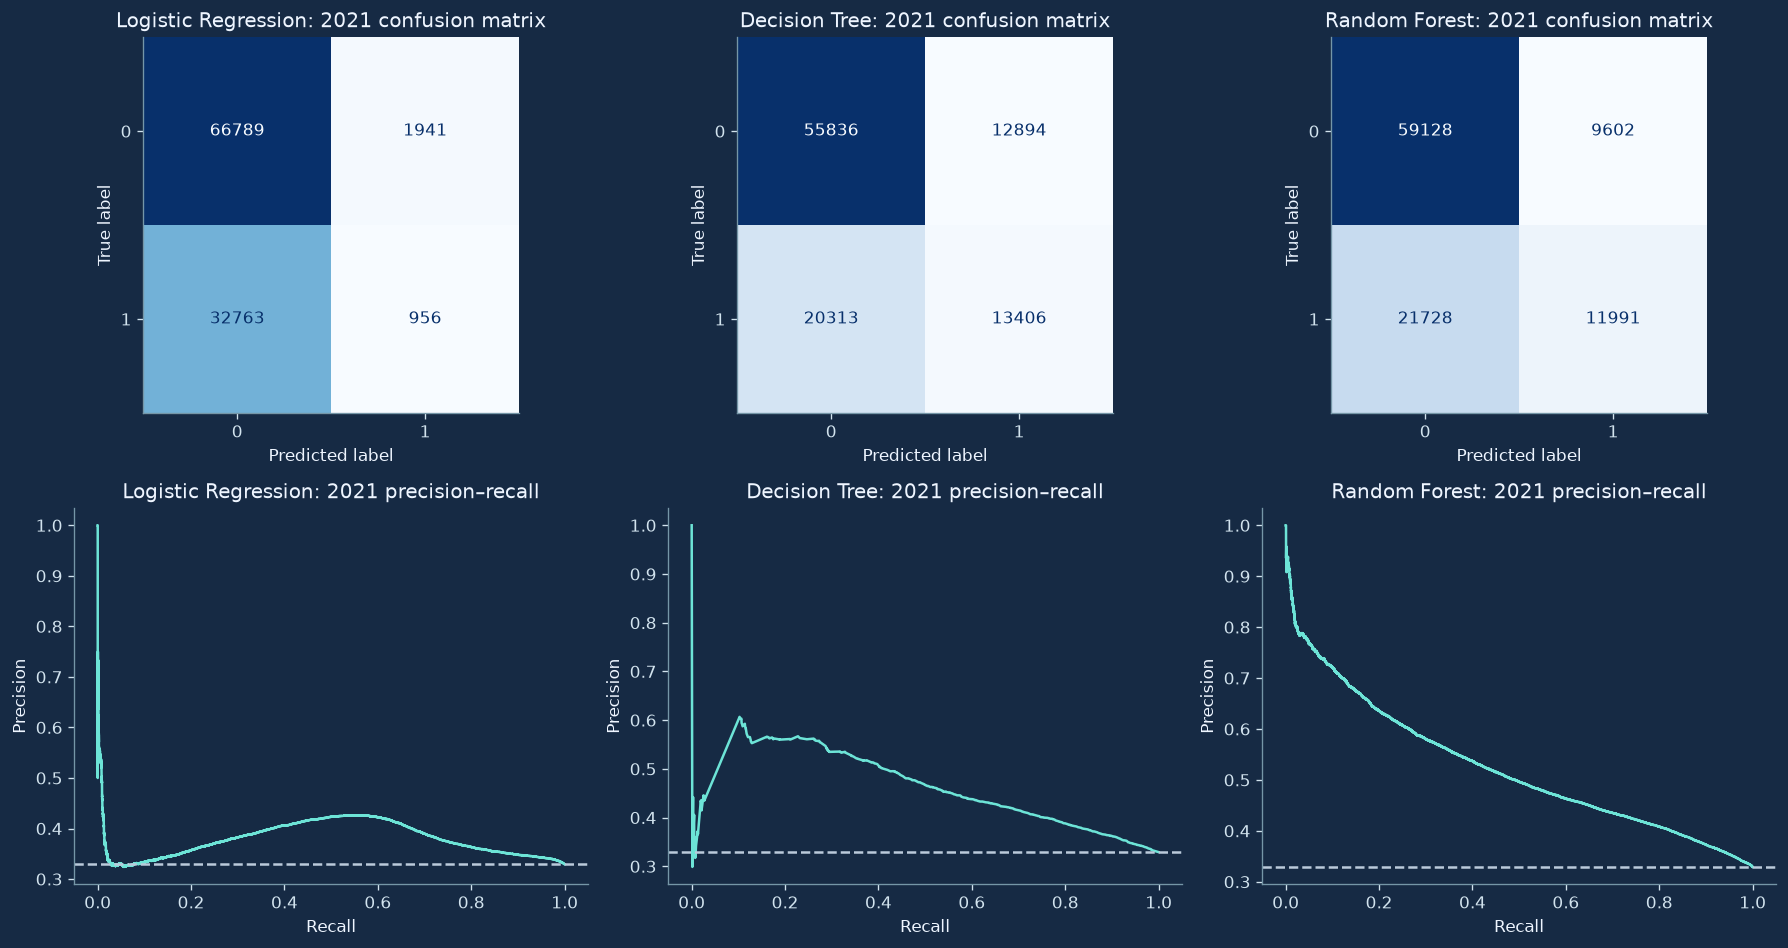

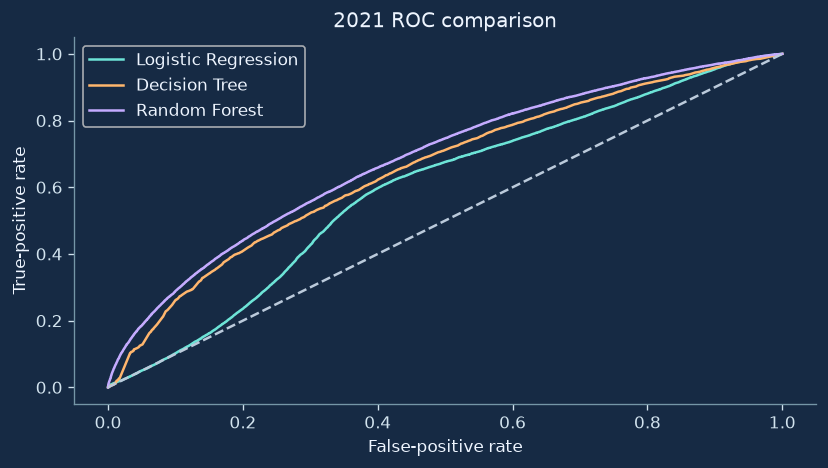

In [13]:
# Use the same saved score vector for both discrimination plots.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, name in enumerate(MODEL_NAMES):
    result = selected_by_model[name]
    ConfusionMatrixDisplay(np.asarray(result['validation']['confusion_matrix']), display_labels=[0, 1]).plot(
        ax=axes[0, j], colorbar=False, cmap='Blues', values_format='d')
    axes[0, j].set_title(f'{name}: 2021 confusion matrix')
    scores = result['validation_predictions'].probability
    precision, recall, _ = precision_recall_curve(validation.candidate_y, scores)
    axes[1, j].plot(recall, precision, color='#6DE4D7')
    axes[1, j].axhline(validation.candidate_y.mean(), color='#BBCADB', linestyle='--')
    axes[1, j].set(xlabel='Recall', ylabel='Precision', title=f'{name}: 2021 precision–recall')
plt.show()

# The diagonal is the no-skill ROC reference.
fig, ax = plt.subplots(figsize=(7, 4))
for name, result in selected_by_model.items():
    fpr, tpr, _ = roc_curve(validation.candidate_y, result['validation_predictions'].probability)
    ax.plot(fpr, tpr, label=name)
ax.plot([0, 1], [0, 1], linestyle='--', color='#BBCADB')
ax.set(xlabel='False-positive rate', ylabel='True-positive rate', title='2021 ROC comparison')
ax.legend(facecolor='#162A44', labelcolor='#EEF5FF')
plt.show()

### Error analysis — what fails and where?

Evaluate the selected classifier's mistakes by county and historical period (metadata **not** included in X). Show bounded actual false-positive/negative examples. Do not mistake correlated 15-minute anchors for independent incidents or infer whether a utility restored service.

In [14]:
# Reuse the chosen configuration's actual 2021 scores and classes.
errors = selected_by_model[WINNER_NAME]['validation_predictions'].copy()
winner_scores = errors.probability.to_numpy()
# The two flags distinguish missed escalations from false alerts.
errors['FN'] = (errors.candidate_y == 1) & (errors.prediction == 0)
errors['FP'] = (errors.candidate_y == 0) & (errors.prediction == 1)
errors['month'] = errors.timestamp.dt.strftime('%Y-%m')
errors['current_count'] = validation.customers_out_t.to_numpy()
errors['missing_history'] = validation[['lag_15m_missing', 'lag_60m_missing']].any(axis=1).to_numpy()

# Use class-specific denominators when comparing periods with different prevalence.
group_tables = []
for group in ['fips_code', 'month', 'missing_history']:
    summary = errors.groupby(group).agg(anchors=('candidate_y', 'size'), positives=('candidate_y', 'sum'),
                                        FP=('FP', 'sum'), FN=('FN', 'sum')).reset_index()
    summary['FNR'] = summary.FN / summary.positives.replace(0, np.nan)
    summary['FPR'] = summary.FP / (summary.anchors - summary.positives).replace(0, np.nan)
    summary.to_csv(REPORT_DIR / f'error_by_{group}.csv', index=False)
    group_tables.append(summary)
    display(summary)
# Show high-score false positives and low-score false negatives separately.
false_positives = errors.loc[errors.FP].nlargest(5, 'probability')
false_negatives = errors.loc[errors.FN].nsmallest(5, 'probability')
display(pd.concat([false_positives, false_negatives], ignore_index=True))
county_errors = group_tables[0]
display(Markdown(f"**2021 errors:** {errors.FP.sum():,} false positives and {errors.FN.sum():,} false negatives. "
                 f"The county false-negative rates span {county_errors.FNR.min():.1%}–{county_errors.FNR.max():.1%}. "
                 "These differences describe the observed cohort and may reflect differences in reporting and event mix."))

fips_code  anchors  positives    FP     FN       FNR       FPR
0     06037    34476      14820  1354  10751  0.725439  0.068885
1     12086    34057      10113  4151   5865  0.579947  0.173363
2     48201    33916       8786  4097   5112  0.581835  0.163032

month  anchors  positives    FP    FN       FNR       FPR
0   2021-01     8755       2475   440  1917  0.774545  0.070064
1   2021-02     7851       2388   349  1822  0.762982  0.063884
2   2021-03     8755       2817   572  1934  0.686546  0.096329
3   2021-04     8372       2692   793  1860  0.690936  0.139613
4   2021-05     8798       3006  1132  1814  0.603460  0.195442
5   2021-06     8560       3427   985  2182  0.636708  0.191896
6   2021-07     8876       3350  1047  1930  0.576119  0.189468
7   2021-08     8610       3180  1036  1850  0.581761  0.190792
8   2021-09     8603       2989   914  1751  0.585815  0.162807
9   2021-10     8651       2886   866  1722  0.596674  0.150217
10  2021-11     8372       2280   747  1447  0.634649  0.122620
11  2021-12     8246       2229   721  1499  0.672499  0.119827

missing_history  anchors  positives    FP     FN       FNR       FPR
0            False   102088      33583  9558  21678  0.645505  0.139523
1             True      361        136    44     50  0.367647  0.195556

fips_code                 timestamp  candidate_y  probability  prediction  \
0     06037 2021-04-08 13:15:00+00:00            0     0.729862           1   
1     12086 2021-05-05 13:45:00+00:00            0     0.724036           1   
2     48201 2021-06-02 14:00:00+00:00            0     0.714549           1   
3     12086 2021-08-19 13:30:00+00:00            0     0.710015           1   
4     12086 2021-08-19 13:45:00+00:00            0     0.708976           1   
5     06037 2021-12-14 07:15:00+00:00            1     0.030971           0   
6     06037 2021-12-14 07:30:00+00:00            1     0.038379           0   
7     06037 2021-10-05 03:15:00+00:00            1     0.039144           0   
8     06037 2021-01-19 23:30:00+00:00            1     0.039767           0   
9     06037 2021-12-14 08:30:00+00:00            1     0.040025           0   

      FN     FP    month  current_count  missing_history  
0  False   True  2021-04            5.0            False  
1  False   True  2021-05          139.0            False  
2  False   True  2021-06          241.0            False  
3  False   True  2021-08           76.0            False  
4  False   True  2021-08           82.0            False  
5   True  False  2021-12         5774.0            False  
6   True  False  2021-12         5813.0            False  
7   True  False  2021-10         9369.0            False  
8   True  False  2021-01        21283.0            False  
9   True  False  2021-12         5778.0            False

**2021 errors:** 9,602 false positives and 21,728 false negatives. The county false-negative rates span 58.0%–72.5%. These differences describe the observed cohort and may reflect differences in reporting and event mix.

#### Understanding the code — evaluation and errors

Precision uses predicted positives as its denominator. Recall uses observed positives. FNR and FPR use different observed-class denominators. AP and ROC-AUC rank scores across thresholds. **TA question:** Why can a model have high AP and weak recall? **Answer:** It may rank positives correctly while many still score below the fixed 0.5 classification rule.

### Reliability and probability calibration

A sigmoid output or a Random Forest vote fraction does **not** by itself prove calibrated probabilities. Report Brier score and a validation reliability diagram; label the app output a **model score** unless calibration has been established and independently checked. If a calibrated probability is eventually needed, fit a calibrator on training-only folds and test it without using 2022 for tuning.

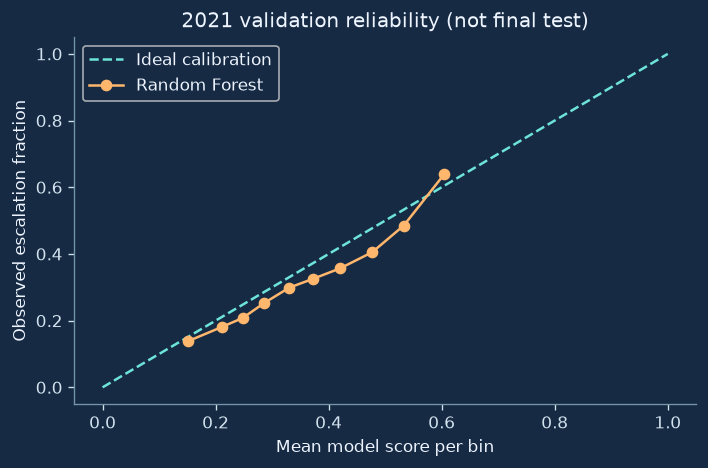

2021 Brier score: 0.20144846766030158
Interpret scores cautiously: time-overlap, model selection, class imbalance and reporting gaps affect reliability.


In [15]:
actual = validation['candidate_y'].to_numpy()
score = winner_scores
# Quantile bins compare similar-sized groups of sorted scores.
fraction_positive, mean_predicted = calibration_curve(actual, score, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([0,1],[0,1], linestyle='--', label='Ideal calibration')
ax.plot(mean_predicted, fraction_positive, marker='o', label=WINNER_NAME)
ax.set(xlabel='Mean model score per bin', ylabel='Observed escalation fraction',
       title='2021 validation reliability (not final test)')
ax.legend(facecolor='#162A44', labelcolor='#EEF5FF')
plt.show()
print('2021 Brier score:', brier_score_loss(actual, score))
print('Interpret scores cautiously: time-overlap, model selection, class imbalance and reporting gaps affect reliability.')

<a id="task3-xai"></a>
## 06. Explainable AI — global and local behavior

**Global:** model-agnostic permutation importance on a deterministic, bounded **2021 validation** subset shows the degradation in AP after shuffling one feature. Highly correlated features can have misleadingly low individual permutation importance; this is not causality.

**Local:** a one-feature-at-a-time replacement with a training median measures a particular prediction's **model-score sensitivity**. Correlated or physically linked features can make such counterfactual combinations unrealistic; results are **not additive SHAP values**. If SHAP is installed and time permits, it can supplement this analysis after validating runtime and version compatibility.

feature  mean_AP_decrease_when_shuffled  std_across_repeats
7               hour_utc                    1.728438e-01        1.122596e-02
0        customers_out_t                    4.848699e-02        2.831047e-03
8            weekday_utc                    2.873765e-02        4.436324e-03
9              month_utc                    8.603734e-03        2.430286e-03
1                lag_15m                    7.866956e-03        2.485639e-03
5   rolling_variance_60m                    4.828941e-03        7.578517e-04
2                lag_60m                    3.182612e-03        3.425342e-03
4       rolling_mean_60m                    5.340037e-04        1.719396e-03
12     delta_60m_missing                    9.653169e-05        1.425434e-05
10       lag_15m_missing                   -7.933009e-07        2.257420e-07
6      history_slots_60m                   -5.509560e-06        8.550891e-05
11       lag_60m_missing                   -2.654274e-05        2.316017e-05
3              delta_60m                   -3.437018e-03        7.281546e-03

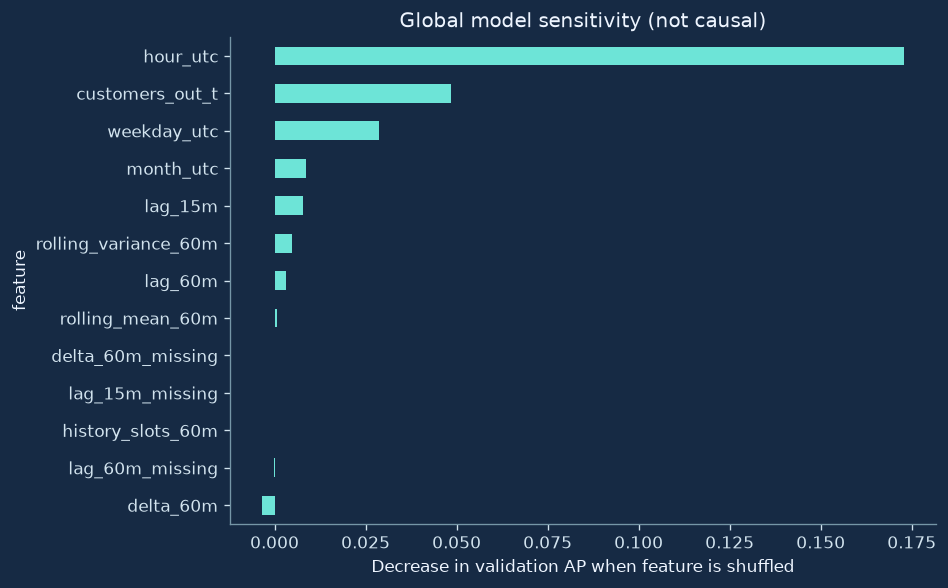

**Global finding:** shuffling hour_utc caused the largest mean AP drop (0.173) in the fixed 2021 sample. This sensitivity can reflect how and when reports are observed.

In [16]:
# Shuffle one input at a time in the same seeded 2021 sample and rescore AP.
explanation_frame = validation.sample(n=min(1500, len(validation)), random_state=RANDOM_SEED)
importance = permutation_importance(
    WINNER_DEV,
    explanation_frame[FEATURE_COLUMNS],
    explanation_frame['candidate_y'],
    scoring='average_precision',
    n_repeats=3,
    random_state=RANDOM_SEED,
    n_jobs=1,
)
importance_table = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'mean_AP_decrease_when_shuffled': importance.importances_mean,
    'std_across_repeats': importance.importances_std,
}).sort_values('mean_AP_decrease_when_shuffled', ascending=False)
display(importance_table)
importance_table.sort_values('mean_AP_decrease_when_shuffled').plot.barh(
    x='feature', y='mean_AP_decrease_when_shuffled', legend=False, figsize=(8,5))
plt.xlabel('Decrease in validation AP when feature is shuffled')
plt.title('Global model sensitivity (not causal)'); plt.tight_layout(); plt.show()

# A calendar predictor can be informative through reporting and seasonal effects.
top_feature = importance_table.iloc[0]
display(Markdown(f"**Global finding:** shuffling {top_feature.feature} caused the largest mean AP drop "
                 f"({top_feature.mean_AP_decrease_when_shuffled:.3f}) in the fixed 2021 sample. "
                 "This sensitivity can reflect how and when reports are observed."))


In [17]:
# Local explanation for a real eligible validation anchor; no 2022 data accessed.
local_row = validation.iloc[[0]][FEATURE_COLUMNS].copy()
original_score = float(WINNER_DEV.predict_proba(local_row)[0,1])
train_medians = train[FEATURE_COLUMNS].median(numeric_only=True)
local_effects = []
for feature_name in FEATURE_COLUMNS:
    # Replace one value and keep the other twelve inputs fixed.
    modified = local_row.copy()
    modified.loc[modified.index[0], feature_name] = train_medians[feature_name]
    new_score = float(WINNER_DEV.predict_proba(modified)[0,1])
    local_effects.append({
        'feature': feature_name,
        'original_value': local_row.iloc[0][feature_name],
        'training_median_reference': train_medians[feature_name],
        'score_change_when_replaced': new_score - original_score,
    })
local_table = pd.DataFrame(local_effects).sort_values('score_change_when_replaced')
print('Original single-instance model score:', original_score)
display(local_table)
print('These are one-at-a-time sensitivity checks; replacing linked lag/delta values can produce unrealistic combinations.')

# Print which observed anchor was explained and the largest score movement.
largest_effect = local_table.loc[local_table.score_change_when_replaced.abs().idxmax()]
display(Markdown(f"**Local finding:** county {validation.fips_code.iloc[0]} at "
                 f"{validation.timestamp.iloc[0].isoformat()} received score {original_score:.3f}. "
                 f"Replacing {largest_effect.feature} with its training median moved that score "
                 f"by {largest_effect.score_change_when_replaced:+.3f} with the other inputs held fixed."))


Original single-instance model score: 0.2748735966610068


feature  original_value  training_median_reference  \
6      history_slots_60m             1.0                       5.00   
4       rolling_mean_60m          1507.0                     293.60   
10       lag_15m_missing             1.0                       0.00   
12     delta_60m_missing             1.0                       0.00   
11       lag_60m_missing             1.0                       0.00   
3              delta_60m             NaN                      -3.00   
1                lag_15m             NaN                     259.00   
2                lag_60m             NaN                     259.00   
8            weekday_utc             6.0                       4.00   
0        customers_out_t          1507.0                     259.00   
5   rolling_variance_60m             0.0                    1617.36   
9              month_utc             1.0                       7.00   
7               hour_utc             0.0                      12.00   

    score_change_when_replaced  
6                    -0.015694  
4                    -0.012000  
10                   -0.002060  
12                   -0.001532  
11                   -0.001248  
3                     0.000000  
1                     0.000000  
2                     0.000000  
8                     0.009993  
0                     0.014082  
5                     0.014206  
9                     0.023498  
7                     0.097617

These are one-at-a-time sensitivity checks; replacing linked lag/delta values can produce unrealistic combinations.


**Local finding:** county 06037 at 2021-01-01T00:00:00+00:00 received score 0.275. Replacing hour_utc with its training median moved that score by +0.098 with the other inputs held fixed.

<a id="task3-ablation"></a>
## 07. With-vs-without engineered features (feature ablation)

The final ML requirements ask for this **where feasible**. A transparent comparison uses the selected estimator and equal 2018–2020/2021 populations with (A) **only the original current outage count** versus (B) the 13 engineered/current numeric inputs. We do not retune on the outcome of this diagnostic or use 2022. A single-feature baseline is deliberately simple and might underperform; display the real result without assuming direction.

In [18]:
# Reuse the selected estimator and preprocessing steps with a one-column selector.
raw_columns = ['customers_out_t']
raw_model = make_model(WINNER_NAME, WINNER_PARAMS)
numeric = raw_model.named_steps['prepare'].transformers[0][1]
raw_model.set_params(prepare__transformers=[('numeric', numeric, raw_columns)])
# Fit both preparation and classifier on the same earlier rows as the full model.
raw_seconds, raw_warnings = fit(raw_model, train[raw_columns], train.candidate_y)
raw_metrics = classification_metrics(validation.candidate_y, probability(raw_model, validation[raw_columns]))
full_result = selected_by_model[WINNER_NAME]
feature_ablation = pd.DataFrame([
    {'configuration': 'Current count only', 'features': 1, '2021_AP': raw_metrics['average_precision'],
     '2021_F1': raw_metrics['f1'], 'fit_seconds': raw_seconds, 'warnings': raw_warnings},
    {'configuration': 'Full feature contract', 'features': len(FEATURE_COLUMNS),
     '2021_AP': full_result['validation']['average_precision'],
     '2021_F1': full_result['validation']['f1'], 'fit_seconds': full_result['fit_seconds'],
     'warnings': full_result['warnings']},
])
display(feature_ablation)
ap_difference = feature_ablation['2021_AP'].iloc[1] - feature_ablation['2021_AP'].iloc[0]
print(f'2021 AP difference, full features minus current count: {ap_difference:+.4f}')
feature_ablation.to_csv(REPORT_DIR / 'feature_ablation.csv', index=False)

configuration  features   2021_AP   2021_F1  fit_seconds warnings
0     Current count only         1  0.374590  0.006116    19.175803       []
1  Full feature contract        13  0.523669  0.433577    42.998228       []

2021 AP difference, full features minus current count: +0.1491


<a id="task3-freeze"></a>
## 08. Freeze the winner, refit on 2018–2021, save complete pipeline

The winner and settings were decided **without 2022**. Final refit on both the 2018–2020 train data and 2021 validation is allowed *after* development selection is frozen. Its saved `joblib` includes the **imputer + scaler + classifier**, feature schema and metadata. This same artifact will later power Streamlit. Loading arbitrary untrusted joblib files is unsafe; only load an artifact created by this project.

The frozen metadata records the selection, approved target, versions, threshold, ordered input schema and artifact checksum. The pre-holdout file and the eventual final-evaluation output use separate paths.

In [19]:
# Refit the frozen specification on all eligible 2018–2021 development observations.
artifact_metadata = freeze_pipeline(ROOT, frame, selection, approval)
display(pd.DataFrame([{'model': WINNER_NAME, 'parameters': WINNER_PARAMS,
                       'development anchors': artifact_metadata['development_rows'],
                       'refit seconds': artifact_metadata['fit_seconds'],
                       'threshold': artifact_metadata['decision_threshold']}]))
print('Model:', artifact_metadata['artifact'])
print('SHA-256:', artifact_metadata['artifact_sha256'])

model  \
0  Random Forest   

                                                       parameters  \
0  {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 10}   

   development anchors  refit seconds  threshold  
0               406240      50.571869        0.5

Model: artifacts/modeling/frozen_development_pipeline.joblib
SHA-256: 613e3b445373492f17fea2fd3f62a61fef5f1bc1a8e33e8d8fb6357e97b28d2b


### Reload proof — separate fresh Python process

**Why?** A model that scores in a notebook's current memory may still fail when loaded by the app. This check loads the exact saved `joblib` **in a child Python process** and compares its output to our in-memory model on 100 development observations sampled across the fixed cohort. There is no 2022 access.

In [20]:
# The child process loads the exact artifact and checks the saved 100-anchor fixture.
reload_proof = verify_development_reload(ROOT)
display(pd.DataFrame([{'rows': reload_proof['rows'], 'fresh process': reload_proof['fresh_process'],
                       'maximum score difference': reload_proof['maximum_score_error'],
                       'status': reload_proof['status']}]))

rows  fresh process  maximum score difference    status
0   100           True                       0.0  VERIFIED

#### Understanding the code — saving and reloading

The artifact stores the fitted preprocessing and estimator. SHA-256 checks whether the saved bytes match the metadata. **TA question:** What does the fresh process actually compare? **Answer:** It predicts the same 100 development feature rows and checks that each label and score exactly matches the values captured before serialization.

<a id="task3-sealed"></a>
## 09. Final held-out evaluation — one-time approval gate

2022 is reserved for a separately authorized run through `scripts/evaluate_final.py`. The existing final-evaluation module owns the once-only journal. The development notebook has no path that opens 2022. Review the frozen metadata, reload proof and runtime prerequisites before approving the holdout.

In [21]:
# Only check journal presence. This notebook has no holdout execution cell.
journal = REPORT_DIR / 'final_evaluation_journal.json'
print('2022 gate:', 'journal present; see the controlled evaluation record' if journal.exists()
      else 'SEALED — separate approval required before the once-only evaluation')

2022 gate: SEALED — separate approval required before the once-only evaluation


<a id="task3-report"></a>
## 10. Evidence and inference handoff

The model accepts the exact thirteen ordered numeric predictors. Task 2 defines how to compute them using county history available at scoring time. The saved development pipeline includes the imputer, scaler and classifier. Use `gridrescue.inference` for local inference. Application input validation, UX, deployment and the final test are separate deliverables.

In [22]:
# Persist the measured diagnostics behind the notebook tables and charts.
importance_table.to_csv(REPORT_DIR / 'permutation_importance.csv', index=False)
local_table.to_csv(REPORT_DIR / 'local_score_sensitivity.csv', index=False)
pd.DataFrame({'mean_score': mean_predicted, 'observed_fraction': fraction_positive}).to_csv(
    REPORT_DIR / 'reliability_bins.csv', index=False
)
write_json(REPORT_DIR / 'development_diagnostics.json', {
    'winner': WINNER_NAME, '2021_brier': float(brier_score_loss(actual, winner_scores)),
    'constant_prevalence_brier': float(brier_score_loss(actual, np.full(len(actual), train.candidate_y.mean()))),
    '2021_false_positives': int(errors.FP.sum()), '2021_false_negatives': int(errors.FN.sum()),
    'local_anchor_utc': validation.timestamp.iloc[0].isoformat(), 'local_anchor_fips': validation.fips_code.iloc[0],
    'local_score': original_score, '2021_ablation_AP_difference': float(ap_difference), 'holdout_accessed': False,
})
print('Development evidence, frozen metadata and reload verification are in reports/modeling/.')

Development evidence, frozen metadata and reload verification are in reports/modeling/.
